# 01 — Dataset understanding, EDA, and preprocessing

This is report section 2.2 and the repository's data-processing evidence. It uses the **80 train and 10 student-test trips** only. Raw files are inspected before cleaning, while training and prediction both use pathsnap.clean_track. Saved outputs are from the supplied files, not simulated data.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
import joblib
from IPython.display import display
from matplotlib.collections import LineCollection
from pathsnap import Trip, RoadIndex, make_rows, decode, bridge_route, clean_track

DATA_ROOT = Path(os.environ.get("PATHSNAP_DATA_ROOT", "data"))
assert (DATA_ROOT / "train").is_dir() and (DATA_ROOT / "student_test").is_dir(), DATA_ROOT
print("Train folders:", len(list((DATA_ROOT/"train").glob("*/*.track"))))
print("Student-test folders:", len(list((DATA_ROOT/"student_test").glob("*/*.track"))))
print("Each trip has .track (lon,lat,time), .nodes (lon,lat), .arcs (node IDs), .route (reference arc IDs).")

Train folders: 80
Student-test folders: 10
Each trip has .track (lon,lat,time), .nodes (lon,lat), .arcs (node IDs), .route (reference arc IDs).


## Raw-data quality and cleaning

The cleaning function drops nonfinite or impossible coordinates/times, sorts timestamps, removes exact duplicate rows and conflicting same-time observations, then rejects observations requiring speed above 70 m/s from the last retained point. Repeated coordinates at different times remain because a car can stop. Zero removals for a category mean the raw supplied files did not contain that issue; the code still handles it.

GPS quality audit across 90 trips


,observations
raw_points,227577
invalid_rows,0
duplicate_rows,0
timestamp_conflicts,0
timestamps_reordered,0
outlier_rows,177
clean_points,227400


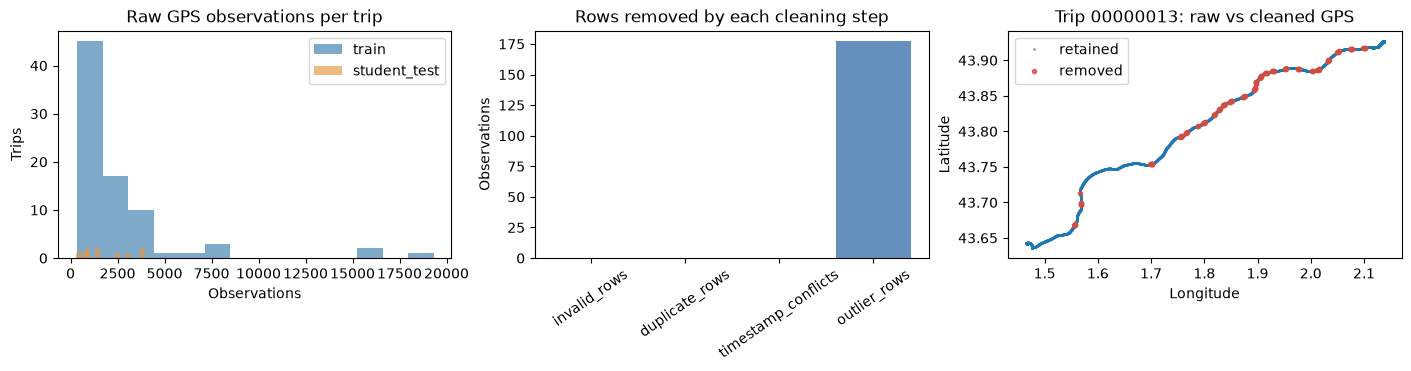

Cleaning uses the same 70 m/s speed cap in training and prediction.


In [2]:
from collections import Counter
from pathsnap import clean_track, MAX_GPS_SPEED_MPS

audit_rows = []
for partition in ("train", "student_test"):
    for path in sorted((DATA_ROOT / partition).glob("*/*.track")):
        raw = np.loadtxt(path, ndmin=2)
        cleaned, counts = clean_track(raw)
        audit_rows.append({"partition": partition, "trip": path.parent.name, **counts})
audit = pd.DataFrame(audit_rows)
totals = audit[["raw_points", "invalid_rows", "duplicate_rows", "timestamp_conflicts", "timestamps_reordered", "outlier_rows", "clean_points"]].sum()
print("GPS quality audit across", len(audit), "trips")
display(totals.rename("observations").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), layout="constrained")
for partition, color in (("train", "#397cad"), ("student_test", "#e7963c")):
    axes[0].hist(audit.loc[audit.partition == partition, "raw_points"], bins=14, alpha=.65, color=color, label=partition)
axes[0].set(title="Raw GPS observations per trip", xlabel="Observations", ylabel="Trips")
axes[0].legend()
counts = totals[["invalid_rows", "duplicate_rows", "timestamp_conflicts", "outlier_rows"]]
axes[1].bar(counts.index, counts.values, color="#658fbc")
axes[1].tick_params(axis="x", rotation=35)
axes[1].set(title="Rows removed by each cleaning step", ylabel="Observations")
example = audit.sort_values("outlier_rows", ascending=False).iloc[0]
example_path = DATA_ROOT / example.partition / example.trip / (example.trip + ".track")
raw = np.loadtxt(example_path, ndmin=2)
cleaned, _ = clean_track(raw)
retained = {tuple(row) for row in cleaned}
removed = np.asarray([row for row in raw if tuple(row) not in retained]).reshape(-1, 3)
axes[2].plot(cleaned[:, 0], cleaned[:, 1], ".", ms=2, alpha=.55, label="retained")
axes[2].plot(removed[:, 0], removed[:, 1], "o", ms=3, alpha=.8, color="#d14d43", label="removed")
axes[2].set(title=f"Trip {example.trip}: raw vs cleaned GPS", xlabel="Longitude", ylabel="Latitude")
axes[2].legend()
plt.show()
print(f"Cleaning uses the same {MAX_GPS_SPEED_MPS:.0f} m/s speed cap in training and prediction.")

## GPS trajectory and road network — student-test trip 00000052

Blue = recorded GPS points; grey = nearby road arcs; orange = supplied reference route. The reference is shown here for analysis only and never passed into the prediction model.

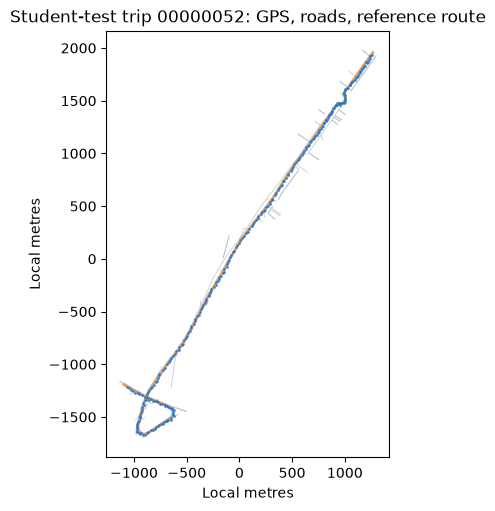

GPS observations: 262 nodes: 1770 arcs: 3577 reference arc entries: 95


In [3]:
trip = Trip.load(DATA_ROOT/"student_test"/"00000052", include_route=True)
road, ids, candidates, x, labels = make_rows(trip, max_points=300)
nearby = np.unique(candidates.ravel())
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.add_collection(LineCollection(np.stack((road.a[nearby],road.b[nearby]),axis=1),colors="#aab7c6",linewidths=.6,alpha=.7))
ref = np.unique(trip.route)
ax.add_collection(LineCollection(np.stack((road.a[ref],road.b[ref]),axis=1),colors="#e58b33",linewidths=2,alpha=.8))
ax.plot(road.track_xy[:,0],road.track_xy[:,1],".",markersize=2,color="#2779d1",alpha=.8)
ax.autoscale(); ax.set_aspect("equal",adjustable="box")
ax.set(title="Student-test trip 00000052: GPS, roads, reference route",xlabel="Local metres",ylabel="Local metres")
plt.show()
print("GPS observations:",len(trip.track),"nodes:",len(trip.nodes),"arcs:",len(trip.arcs),"reference arc entries:",len(trip.route))

## Required interactive Folium geographical map

This real latitude/longitude map uses distinct layers for original GPS observations, nearby roads, the reference route, and the predicted route, with layer controls and extent fitted to the trip. It is generated from trip 00000052 in the **student-test** partition. The same code saves a standalone HTML map in the artifacts folder.

In [4]:
model = joblib.load("artifacts/final_model.joblib")
scores = model.predict_proba(x.reshape(-1,x.shape[-1]))[:,1].reshape(candidates.shape)
chosen = decode(trip,road,ids,candidates,scores)
routed, inserted, unresolved = bridge_route(trip,road,chosen)
center = [float(trip.track[:,1].mean()),float(trip.track[:,0].mean())]
m = folium.Map(location=center, zoom_start=14, tiles=None, control_scale=True)
roads = folium.FeatureGroup(name="Nearby road network",show=True)
gps = folium.FeatureGroup(name="Original GPS observations",show=True)
reference = folium.FeatureGroup(name="Reference route",show=True)
predicted = folium.FeatureGroup(name="Predicted route",show=True)
for arc in nearby:
    a,b=trip.arcs[arc]
    folium.PolyLine([trip.nodes[a,::-1].tolist(),trip.nodes[b,::-1].tolist()],color="#aab7c6",weight=1,opacity=.45).add_to(roads)
for lon,lat,_ in trip.track:
    folium.CircleMarker([lat,lon],radius=2,color="#2779d1",fill=True,fill_opacity=.7).add_to(gps)
for arc in dict.fromkeys(trip.route.tolist()):
    a,b=trip.arcs[arc]
    folium.PolyLine([trip.nodes[a,::-1].tolist(),trip.nodes[b,::-1].tolist()],color="#e58b33",weight=5,opacity=.8).add_to(reference)
for arc in dict.fromkeys(routed.tolist()):
    a,b=trip.arcs[arc]
    folium.PolyLine([trip.nodes[a,::-1].tolist(),trip.nodes[b,::-1].tolist()],color="#11976b",weight=3,opacity=.9).add_to(predicted)
for layer in (roads,reference,predicted,gps): layer.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.fit_bounds([[float(trip.track[:,1].min()),float(trip.track[:,0].min())],
              [float(trip.track[:,1].max()),float(trip.track[:,0].max())]])
m.save("artifacts/folium_trip_00000052.html")
display(m)
print("Saved interactive Folium HTML; bridges inserted:",inserted,"unresolved:",unresolved)

Saved interactive Folium HTML; bridges inserted: 35 unresolved: 9


## EDA conclusion

The raw student folder has 90 trips and 227,577 GPS observations. The cleaning audit found no invalid coordinates, exact duplicate rows, or timestamp conflicts; it removed 177 implausible speed observations and retained 227,400. Trip sizes and time gaps vary substantially, and many road graphs have disconnected components. The road and GPS plots demonstrate why nearest-road distance alone is insufficient and why temporal route decoding is needed. The reference route is a whole-path arc sequence, not a verified arc label for every GPS point.